<a href="https://colab.research.google.com/github/ANSH696969/Expoplanets/blob/main/Expoplanets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Dataset Shape & First Look ---
Total records: 1035 discoveries | Columns: 6


,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009
5,Radial Velocity,1,185.840,4.80,76.39,2008


/tmp/ipykernel_1244/1029080365.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


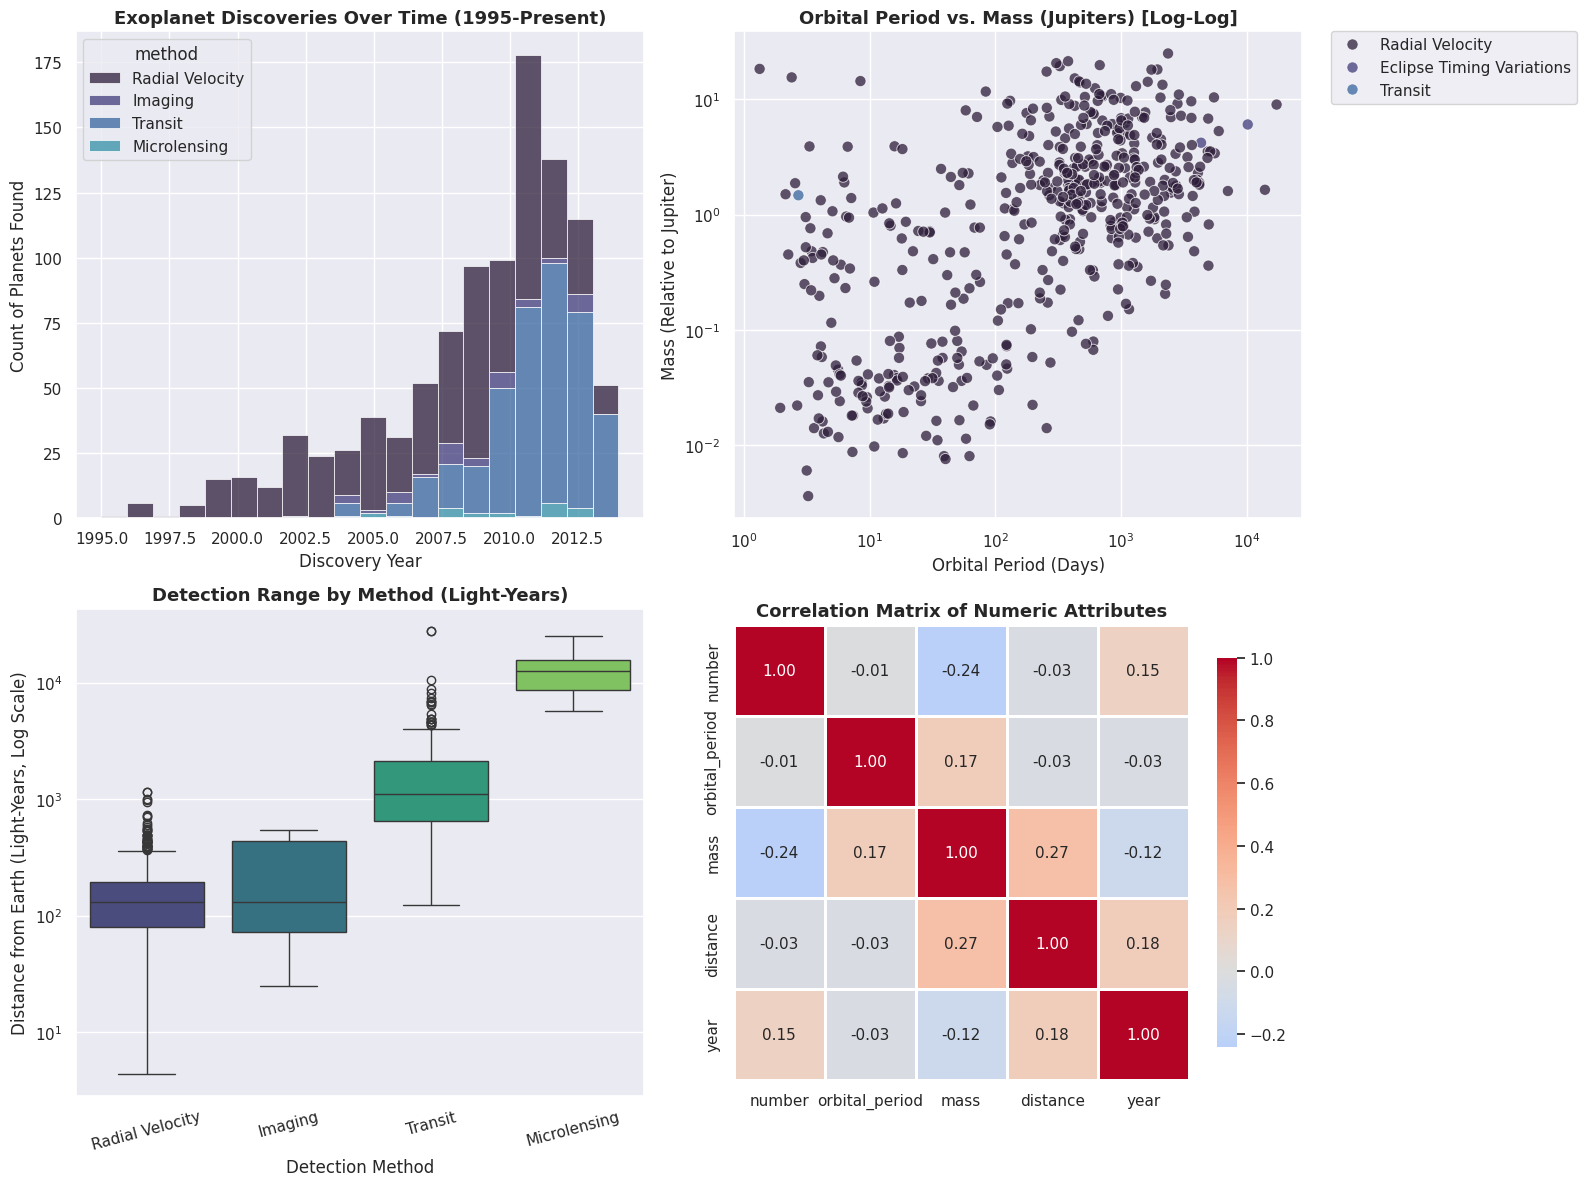


--- Key Statistical Insights ---
1. Most Dominant Discovery Method: Radial Velocity (553 planets)
2. Farthest Exoplanet Detected: 27,710.0 light-years away
3. Heaviest Exoplanet: 25.0x Jupiter's mass
4. Shortest Orbital Period: 0.0907 days (~2.2 hours)


In [ ]:

# 1. SETUP & DATA INGESTION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Style configuration
sns.set_theme(style="darkgrid", palette="mako")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

# Load the built-in Exoplanet dataset
df = sns.load_dataset("planets")

print("--- Dataset Shape & First Look ---")
print(f"Total records: {df.shape[0]} discoveries | Columns: {df.shape[1]}")
display(df.head(6))

# Quick clean: Focus on top discovery methods to avoid long-tail clutter
top_methods = df["method"].value_counts().nlargest(4).index
df_top = df[df["method"].isin(top_methods)].copy()


# 2. EXPLORATORY DATA ANALYSIS & VISUALIZATION

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Chart 1: Timeline of Discoveries by Detection Method

sns.histplot(
    data=df_top[df_top["year"] >= 1995],
    x="year",
    hue="method",
    multiple="stack",
    bins=20,
    ax=axes[0, 0],
    edgecolor="white",
    linewidth=0.5
)
axes[0, 0].set_title("Exoplanet Discoveries Over Time (1995-Present)", fontsize=13, weight="bold")
axes[0, 0].set_xlabel("Discovery Year")
axes[0, 0].set_ylabel("Count of Planets Found")


# Chart 2: Orbital Period vs Planet Mass (Log Scale)

sns.scatterplot(
    data=df.dropna(subset=["orbital_period", "mass"]),
    x="orbital_period",
    y="mass",
    hue="method",
    alpha=0.75,
    s=65,
    ax=axes[0, 1]
)
axes[0, 1].set_xscale("log")
axes[0, 1].set_yscale("log")
axes[0, 1].set_title("Orbital Period vs. Mass (Jupiters) [Log-Log]", fontsize=13, weight="bold")
axes[0, 1].set_xlabel("Orbital Period (Days)")
axes[0, 1].set_ylabel("Mass (Relative to Jupiter)")
axes[0, 1].legend(bbox_to_anchor=(1.05, 1), loc="upper left", borderaxespad=0.)

# Chart 3: Detection Reach (Distance from Earth in Light-Years)

# Distance is in parsecs; multiply by 3.26 for light-years
df_dist = df_top.dropna(subset=["distance"]).copy()
df_dist["dist_ly"] = df_dist["distance"] * 3.26

sns.boxplot(
    data=df_dist,
    x="method",
    y="dist_ly",
    palette="viridis",
    ax=axes[1, 0]
)
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("Detection Range by Method (Light-Years)", fontsize=13, weight="bold")
axes[1, 0].set_xlabel("Detection Method")
axes[1, 0].set_ylabel("Distance from Earth (Light-Years, Log Scale)")
axes[1, 0].tick_params(axis="x", rotation=15)


# Chart 4: Correlation Heatmap of Physical Properties

numeric_cols = ["number", "orbital_period", "mass", "distance", "year"]
corr_matrix = df[numeric_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=1,
    cbar_kws={"shrink": 0.8},
    ax=axes[1, 1]
)
axes[1, 1].set_title("Correlation Matrix of Numeric Attributes", fontsize=13, weight="bold")

plt.tight_layout()
plt.show()


# 3. STATISTICAL SUMMARY INSIGHTS

print("\n--- Key Statistical Insights ---")
print(f"1. Most Dominant Discovery Method: {df['method'].value_counts().index[0]} ({df['method'].value_counts().iloc[0]} planets)")
print(f"2. Farthest Exoplanet Detected: {df['distance'].max() * 3.26:,.1f} light-years away")
print(f"3. Heaviest Exoplanet: {df['mass'].max():.1f}x Jupiter's mass")
print(f"4. Shortest Orbital Period: {df['orbital_period'].min():.4f} days (~{df['orbital_period'].min()*24:.1f} hours)")